# Ficheros · Mil millones de filas

Versión en Python del [One Billion Row Challenge](https://github.com/gunnarmorling/1brc) (1BRC). Un fichero de texto tiene una medida de temperatura por línea con el formato `<estación>;<temperatura>`, siempre con un decimal. Hay que calcular la mínima, la media y la máxima de cada estación y mostrarlas ordenadas por nombre así: `{Abha=-23.0/18.0/59.2, Abidjan=-16.2/26.0/67.3, ...}`, redondeadas a un decimal.

El reto original son $10^9$ filas (unos 13 GB). Aquí se usan 5 millones para que el notebook tarde poco y se extrapola el tiempo a mil millones. Todas las versiones recorren el fichero una vez: $O(n)$ en tiempo y $O(e)$ en memoria, con $e$ el número de estaciones.

## 1. Generar el fichero de medidas

Crear `medidas.txt` con 5 millones de filas. Cada estación tiene una temperatura media y cada medida sale de una normal con esa media y desviación 10, redondeada a un decimal y limitada a $[-99.9, 99.9]$.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd

FILAS = 5_000_000
FICHERO = Path("medidas.txt")

# Temperatura media anual aproximada de cada estación
ESTACIONES = {
    "Abha": 18.0, "Abidjan": 26.0, "Abéché": 29.4, "Accra": 26.4, "Addis Ababa": 16.0,
    "Adelaide": 17.3, "Bulawayo": 18.9, "Bridgetown": 27.1, "Conakry": 26.4, "Cracow": 9.3,
    "Hamburg": 9.7, "Istanbul": 13.9, "Palembang": 27.3, "Roseau": 26.2, "St. John's": 5.0,
    "Las Palmas de Gran Canaria": 21.2, "Santa Cruz de Tenerife": 21.5, "Madrid": 15.0,
    "Reikiavik": 4.3, "Yakutsk": -8.8, "Dubái": 26.9, "Singapur": 27.0, "Oslo": 5.7,
    "Ciudad de México": 17.5, "Buenos Aires": 17.9, "Nairobi": 17.8, "Tokio": 15.4,
    "Sídney": 17.7, "Nueva York": 12.9, "El Cairo": 21.4,
}

def genera_medidas(ruta, filas, semilla=1):
    rng = np.random.default_rng(semilla)
    nombres = np.array(list(ESTACIONES))
    indices = rng.integers(len(nombres), size=filas)
    medias = np.array(list(ESTACIONES.values()))[indices]
    temperaturas = np.clip(np.round(rng.normal(medias, 10), 1), -99.9, 99.9)
    pd.DataFrame({"estacion": nombres[indices], "temperatura": temperaturas}).to_csv(
        ruta, sep=";", header=False, index=False, float_format="%.1f", encoding="utf-8", lineterminator="\n"
    )

inicio = time.perf_counter()
genera_medidas(FICHERO, FILAS)
print(f"{FILAS:,} filas, {FICHERO.stat().st_size / 1e6:.0f} MB en {time.perf_counter() - inicio:.1f} s")
with FICHERO.open(encoding="utf-8") as f:
    print("".join(next(f) for _ in range(5)))

5,000,000 filas, 74 MB en 4.8 s
St. John's;16.3
Las Palmas de Gran Canaria;19.1
Oslo;4.1
Nueva York;1.4
Abidjan;20.8



## 2. Versión directa

Leer el fichero línea a línea, separar por `;`, convertir a `float` y guardar mínimo, máximo, suma y cuenta por estación. Escribir también la función que da el formato de salida. El reto redondea como `Math.round` de Java (mitades hacia arriba), no como `round` de Python, que redondea las mitades al par.

In [2]:
import math

def redondea(x):
    return math.floor(x * 10 + 0.5) / 10

def formato(estadisticas):
    """estadisticas: {estación: (mínimo, media, máximo)} ya en grados."""
    partes = (f"{e}={redondea(mn):.1f}/{redondea(media):.1f}/{redondea(mx):.1f}"
              for e, (mn, media, mx) in sorted(estadisticas.items()))
    return "{" + ", ".join(partes) + "}"

def directa(ruta):
    datos = {}
    with open(ruta, encoding="utf-8") as f:
        for linea in f:
            estacion, valor = linea.split(";")
            t = float(valor)
            d = datos.get(estacion)
            if d is None:
                datos[estacion] = [t, t, t, 1]
            else:
                if t < d[0]:
                    d[0] = t
                if t > d[1]:
                    d[1] = t
                d[2] += t
                d[3] += 1
    return {e: (mn, suma / n, mx) for e, (mn, mx, suma, n) in datos.items()}

assert redondea(0.25) == 0.3 and round(0.25, 1) == 0.2
assert redondea(-0.25) == -0.2

tiempos = {}
inicio = time.perf_counter()
resultado_directo = directa(FICHERO)
tiempos["directa"] = time.perf_counter() - inicio
salida = formato(resultado_directo)
print(salida[:200], "...")
print(f"{tiempos['directa']:.1f} s")

{Abha=-25.3/18.0/63.0, Abidjan=-17.6/26.0/68.4, Abéché=-13.6/29.4/79.8, Accra=-17.3/26.4/70.3, Addis Ababa=-29.7/16.0/60.8, Adelaide=-25.0/17.3/58.6, Bridgetown=-16.5/27.1/70.2, Buenos Aires=-27.5/17. ...
1.6 s


## 3. Bytes y décimas enteras

Probar si la versión anterior mejora leyendo en binario (sin decodificar UTF-8 cada línea) y guardando décimas de grado como enteros, con lo que las sumas son exactas. Los nombres se decodifican solo al final.

In [3]:
def decimas(valor):
    """b'-12.3\n' -> -123 sin pasar por float."""
    return int(valor[:-3] + valor[-2:-1])

def binaria(ruta):
    datos = {}
    with open(ruta, "rb") as f:
        for linea in f:
            estacion, valor = linea.split(b";")
            t = int(valor[:-3] + valor[-2:-1])
            d = datos.get(estacion)
            if d is None:
                datos[estacion] = [t, t, t, 1]
            else:
                if t < d[0]:
                    d[0] = t
                if t > d[1]:
                    d[1] = t
                d[2] += t
                d[3] += 1
    return {e.decode(): (mn / 10, suma / n / 10, mx / 10) for e, (mn, mx, suma, n) in datos.items()}

assert [decimas(v) for v in (b"12.3\n", b"-0.4\n", b"-99.9\n", b"5.0\n")] == [123, -4, -999, 50]

inicio = time.perf_counter()
resultado_binario = binaria(FICHERO)
tiempos["bytes y enteros"] = time.perf_counter() - inicio
assert formato(resultado_binario) == salida
print(f"{tiempos['bytes y enteros']:.1f} s (x{tiempos['directa'] / tiempos['bytes y enteros']:.1f})")

1.7 s (x0.9)


Apenas cambia, e incluso puede ir algo más lento: en CPython casi todo el tiempo se va en ejecutar el bucle del intérprete una vez por fila, no en convertir el texto. Las décimas enteras sí sirven para que las sumas sean exactas y para combinar resultados parciales, que es lo que hace falta en la versión siguiente.

## 4. En paralelo con varios procesos

Partir el fichero en tantos trozos como núcleos, moviendo cada corte hasta el siguiente salto de línea para no partir ninguna fila. Cada proceso calcula los acumulados de su trozo y al final se combinan. En Windows los procesos se crean con *spawn*, así que la función del trabajador va en un módulo (`brc.py`).

In [4]:
%%writefile brc.py
def procesa_trozo(args):
    ruta, inicio, fin = args
    datos = {}
    with open(ruta, "rb") as f:
        f.seek(inicio)
        for linea in f.read(fin - inicio).splitlines():
            estacion, valor = linea.split(b";")
            t = int(valor[:-2] + valor[-1:])
            d = datos.get(estacion)
            if d is None:
                datos[estacion] = [t, t, t, 1]
            else:
                if t < d[0]:
                    d[0] = t
                if t > d[1]:
                    d[1] = t
                d[2] += t
                d[3] += 1
    return datos

Writing brc.py


In [5]:
import os
from concurrent.futures import ProcessPoolExecutor

from brc import procesa_trozo

def trozos(ruta, n):
    tamano = os.path.getsize(ruta)
    cortes = [0]
    with open(ruta, "rb") as f:
        for i in range(1, n):
            f.seek(max(i * tamano // n, cortes[-1]))
            f.readline()  # avanza hasta el final de la fila
            cortes.append(f.tell())
    cortes.append(tamano)
    return [(str(ruta), a, b) for a, b in zip(cortes, cortes[1:]) if a < b]

def combina(parciales):
    total = {}
    for datos in parciales:
        for e, (mn, mx, suma, n) in datos.items():
            d = total.setdefault(e, [mn, mx, 0, 0])
            d[0], d[1] = min(d[0], mn), max(d[1], mx)
            d[2] += suma
            d[3] += n
    return {e.decode(): (mn / 10, suma / n / 10, mx / 10) for e, (mn, mx, suma, n) in total.items()}

def paralela(ruta, procesos=os.cpu_count()):
    with ProcessPoolExecutor(procesos) as ejecutor:
        return combina(ejecutor.map(procesa_trozo, trozos(ruta, procesos)))

# Los trozos cubren el fichero entero sin huecos ni solapes
partes = trozos(FICHERO, 7)
assert partes[0][1] == 0 and partes[-1][2] == FICHERO.stat().st_size
assert all(a[2] == b[1] for a, b in zip(partes, partes[1:]))

inicio = time.perf_counter()
resultado_paralelo = paralela(FICHERO)
tiempos[f"{os.cpu_count()} procesos"] = time.perf_counter() - inicio
assert formato(resultado_paralelo) == salida
print(f"{os.cpu_count()} procesos: {tiempos[f'{os.cpu_count()} procesos']:.1f} s")

16 procesos: 0.5 s


## 5. Con pandas

Resolverlo con `read_csv` y `groupby`. El bucle por filas ya no está en Python sino en el código en C de pandas. Para que la salida coincida exactamente, la media se calcula a partir de la suma y la cuenta en décimas.

In [6]:
def con_pandas(ruta):
    df = pd.read_csv(ruta, sep=";", header=None, names=["estacion", "temperatura"],
                     dtype={"estacion": "category", "temperatura": "float64"})
    df["decimas"] = (df["temperatura"] * 10).round().astype("int64")
    g = df.groupby("estacion", observed=True)["decimas"].agg(["min", "max", "sum", "count"])
    return {e: (f["min"] / 10, f["sum"] / f["count"] / 10, f["max"] / 10) for e, f in g.iterrows()}

inicio = time.perf_counter()
resultado_pandas = con_pandas(FICHERO)
tiempos["pandas"] = time.perf_counter() - inicio
assert formato(resultado_pandas) == salida
print(f"{tiempos['pandas']:.1f} s")

0.2 s


## 6. Comparar y extrapolar

Mostrar los tiempos de cada versión, cuánto tardaría cada una con los mil millones de filas del reto (el coste es lineal) y una gráfica de barras. Borrar después el fichero generado.

versión            5 M filas   10^9 filas
directa                 1.6s       5.2 min
bytes y enteros         1.7s       5.7 min
16 procesos             0.5s       1.7 min
pandas                  0.2s       0.8 min


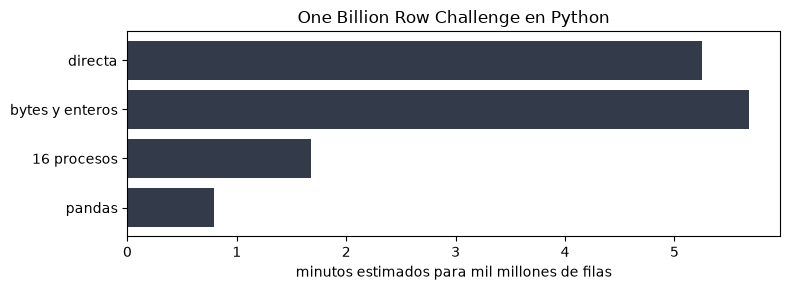

In [7]:
import matplotlib.pyplot as plt

factor = 1_000_000_000 / FILAS
print(f"{'versión':<18}{'5 M filas':>10}{'10^9 filas':>13}")
for nombre, t in tiempos.items():
    print(f"{nombre:<18}{t:>9.1f}s{t * factor / 60:>10.1f} min")

fig, eje = plt.subplots(figsize=(8, 3))
eje.barh(list(tiempos), [t * factor / 60 for t in tiempos.values()], color="#333b4b")
eje.invert_yaxis()
eje.set_xlabel("minutos estimados para mil millones de filas")
eje.set_title("One Billion Row Challenge en Python")
plt.tight_layout()
plt.show()

FICHERO.unlink()
Path("brc.py").unlink()

Las mejores soluciones en Java del reto bajan de 2 segundos con mil millones de filas: leen el fichero con `mmap`, procesan varios bytes a la vez con instrucciones SIMD y usan su propia tabla hash. En Python, el salto grande llega al sacar el bucle del intérprete (pandas, o librerías como Polars o DuckDB) y al usar todos los núcleos.